In [10]:
# Mount Google Drive and Set Paths
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path

# Adjust this to match your actual folder in Drive
base_dir = Path("/content/drive/My Drive/gdsc-drug-response")
raw_csv_path = base_dir / "GDSC_DATASET.csv"

raw_csv_path

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


PosixPath('/content/drive/My Drive/gdsc-drug-response/GDSC_DATASET.csv')

In [11]:
# Import Core Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

In [12]:
# Load the Combined CSV

df = pd.read_csv(raw_csv_path)
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 242035 entries, 0 to 242034
Data columns (total 19 columns):
 #   Column                                   Non-Null Count   Dtype  
---  ------                                   --------------   -----  
 0   COSMIC_ID                                242035 non-null  int64  
 1   CELL_LINE_NAME                           242035 non-null  object 
 2   TCGA_DESC                                240968 non-null  object 
 3   DRUG_ID                                  242035 non-null  int64  
 4   DRUG_NAME                                242035 non-null  object 
 5   LN_IC50                                  242035 non-null  float64
 6   AUC                                      242035 non-null  float64
 7   Z_SCORE                                  242035 non-null  float64
 8   GDSC Tissue descriptor 1                 232669 non-null  object 
 9   GDSC Tissue descriptor 2                 232669 non-null  object 
 10  Cancer Type (matching TCGA label

In [13]:
# Basic Structure and Duplicates Check

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

dup_count = df.duplicated().sum()
print("Duplicate rows:", dup_count)

if dup_count > 0:
    df = df.drop_duplicates()
    print("New shape after dropping duplicates:", df.shape)

Shape: (242035, 19)
Columns: ['COSMIC_ID', 'CELL_LINE_NAME', 'TCGA_DESC', 'DRUG_ID', 'DRUG_NAME', 'LN_IC50', 'AUC', 'Z_SCORE', 'GDSC Tissue descriptor 1', 'GDSC Tissue descriptor 2', 'Cancer Type (matching TCGA label)', 'Microsatellite instability Status (MSI)', 'Screen Medium', 'Growth Properties', 'CNA', 'Gene Expression', 'Methylation', 'TARGET', 'TARGET_PATHWAY']
Duplicate rows: 0


In [14]:
# Quick Summary of Numeric Columns

df.describe(include=[np.number]).T

,count,mean,std,min,25%,50%,75%,max
COSMIC_ID,242035.0,992107.148487,220981.426065,683667.000000,906805.000000,909720.000000,1.240144e+06,1.789883e+06
DRUG_ID,242035.0,1594.044886,398.739728,1003.000000,1149.000000,1631.000000,1.912000e+03,2.499000e+03
LN_IC50,242035.0,2.817111,2.762191,-8.747724,1.508054,3.236744,4.700111e+00,1.382019e+01
AUC,242035.0,0.882593,0.146998,0.006282,0.849452,0.944197,9.749340e-01,9.989040e-01
Z_SCORE,242035.0,0.000006,0.999390,-8.254501,-0.656842,0.010585,6.560365e-01,7.978776e+00


In [15]:
#  Inspect Missingness

missing_frac = df.isna().mean().sort_values(ascending=False)
missing_frac.head(20)

,0
Cancer Type (matching TCGA label),0.212556
TARGET,0.112195
Microsatellite instability Status (MSI),0.051038
Methylation,0.038697
Gene Expression,0.038697
GDSC Tissue descriptor 2,0.038697
GDSC Tissue descriptor 1,0.038697
Screen Medium,0.038697
Growth Properties,0.038697
CNA,0.038697


In [19]:
#  Identify Likely Target and Key ID Columns

response_col = "LN_IC50"
drug_col     = "DRUG_ID"
cell_col     = "CELL_LINE_NAME"

df[[drug_col, cell_col, response_col]].head()

,DRUG_ID,CELL_LINE_NAME,LN_IC50
0,1003,PFSK-1,-1.463887
1,1003,ES5,-3.360586
2,1003,ES7,-5.044940
3,1003,EW-11,-3.741991
4,1003,SK-ES-1,-5.142961


In [20]:
# Drop Rows With Missing Response

before = df.shape[0]
df = df.dropna(subset=[response_col])
after = df.shape[0]

print(f"Dropped {before - after} rows with missing {response_col}.")
print("New shape:", df.shape)

Dropped 0 rows with missing LN_IC50.
New shape: (242035, 19)


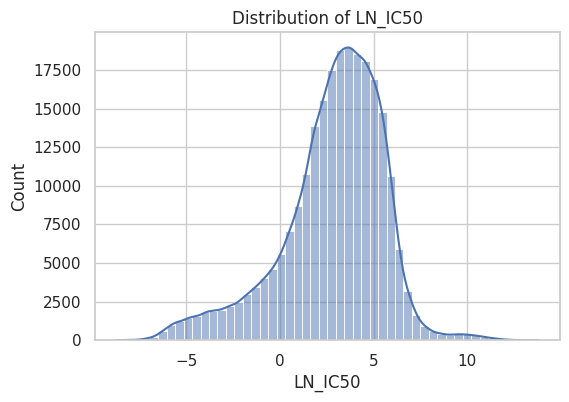

In [21]:
# Look at Response Distribution

plt.figure(figsize=(6,4))
sns.histplot(df[response_col], bins=50, kde=True)
plt.title(f"Distribution of {response_col}")
plt.xlabel(response_col)
plt.ylabel("Count")
plt.show()

In [22]:
# Check Basic Drug and Cell-Line Coverage

print("Number of unique drugs:", df[drug_col].nunique())
print("Number of unique cell lines:", df[cell_col].nunique())

print("\nExample drugs:")
print(df[drug_col].dropna().unique()[:10])

print("\nExample cell lines:")
print(df[cell_col].dropna().unique()[:10])

Number of unique drugs: 295
Number of unique cell lines: 969

Example drugs:
[1003 1004 1005 1006 1007 1008 1009 1010 1011 1012]

Example cell lines:
['PFSK-1' 'ES5' 'ES7' 'EW-11' 'SK-ES-1' 'COLO-829' '5637' 'RT4' 'SW780'
 'TCCSUP']


In [23]:
# Save a Cleaned Snapshot

processed_dir = base_dir / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

clean_path = processed_dir / "gdsc_clean_basic.csv"
df.to_csv(clean_path, index=False)

clean_path

PosixPath('/content/drive/My Drive/gdsc-drug-response/processed/gdsc_clean_basic.csv')